***Cats v/s Dogs Image Classification using CNN***
This notebook implements a Convolutional Neural Network(CNN) to classify images of cats and dogs using TensorFlow and Keras.

The dataset is taken from Kaggle and the model is trained using GPU acceleration.

In [1]:
#Importing necessary python libraries

import numpy as np # linear algebra
import matplotlib.pyplot as plt

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

/kaggle/input/cat-and-dog/test_set/test_set/dogs/dog.4329.jpg
/kaggle/input/cat-and-dog/test_set/test_set/dogs/dog.4223.jpg
/kaggle/input/cat-and-dog/test_set/test_set/dogs/dog.4253.jpg
/kaggle/input/cat-and-dog/test_set/test_set/dogs/dog.4190.jpg
/kaggle/input/cat-and-dog/test_set/test_set/dogs/dog.4354.jpg
/kaggle/input/cat-and-dog/test_set/test_set/dogs/dog.4136.jpg
/kaggle/input/cat-and-dog/test_set/test_set/dogs/dog.4226.jpg
/kaggle/input/cat-and-dog/test_set/test_set/dogs/dog.4214.jpg
/kaggle/input/cat-and-dog/test_set/test_set/dogs/dog.4888.jpg
/kaggle/input/cat-and-dog/test_set/test_set/dogs/dog.4170.jpg
/kaggle/input/cat-and-dog/test_set/test_set/dogs/dog.4323.jpg
/kaggle/input/cat-and-dog/test_set/test_set/dogs/dog.4262.jpg
/kaggle/input/cat-and-dog/test_set/test_set/dogs/dog.4788.jpg
/kaggle/input/cat-and-dog/test_set/test_set/dogs/dog.4657.jpg
/kaggle/input/cat-and-dog/test_set/test_set/dogs/dog.4387.jpg
/kaggle/input/cat-and-dog/test_set/test_set/dogs/dog.4255.jpg
/kaggle/

***Exploring the Dataset Directory***

In [2]:
print("Listing input directory:")
print(os.listdir("/kaggle/input"))

Listing input directory:
['cat-and-dog']


In [3]:
for root, dirs, files in os.walk("/kaggle/input"):
    print(root)

/kaggle/input
/kaggle/input/cat-and-dog
/kaggle/input/cat-and-dog/test_set
/kaggle/input/cat-and-dog/test_set/test_set
/kaggle/input/cat-and-dog/test_set/test_set/dogs
/kaggle/input/cat-and-dog/test_set/test_set/cats
/kaggle/input/cat-and-dog/training_set
/kaggle/input/cat-and-dog/training_set/training_set
/kaggle/input/cat-and-dog/training_set/training_set/dogs
/kaggle/input/cat-and-dog/training_set/training_set/cats


In [4]:
data_dir = "/kaggle/input/cat-and-dog/training_set/training_set"

***Visualizing the Sample Images***

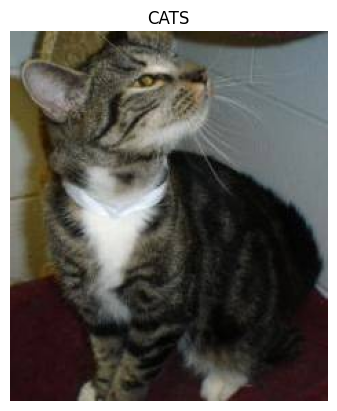

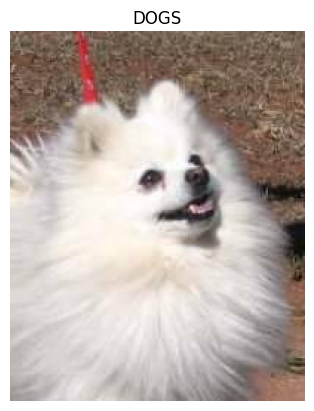

In [5]:
import cv2
import random

categories = ["cats", "dogs"]

for category in categories:
    folder=os.path.join(data_dir, category)
    img_name=random.choice(os.listdir(folder))
    img_path=os.path.join(folder, img_name)

    img=cv2.imread(img_path)
    img=cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    plt.imshow(img)
    plt.title(category.upper())
    plt.axis('off')
    plt.show()

***Image Preprocessing and Data Loading***

In [6]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator
train_dir="/kaggle/input/cat-and-dog/training_set/training_set"
test_dir="/kaggle/input/cat-and-dog/test_set/test_set"

2025-12-24 13:13:00.030115: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1766581980.476853      24 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1766581980.588119      24 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1766581981.649628      24 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1766581981.649670      24 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1766581981.649672      24 computation_placer.cc:177] computation placer alr

In [7]:
train_datagen=ImageDataGenerator(rescale=1/255)
test_datagen=ImageDataGenerator(rescale=1/255)

*The Dataset is divided into:*

1. training data
2. testing data


In [8]:
train_data=train_datagen.flow_from_directory(
    train_dir,
    target_size=(150,150),
    batch_size=32,
    class_mode='binary'
)

test_data=test_datagen.flow_from_directory(
    test_dir,
    target_size=(150, 150),
    batch_size=32,
    class_mode='binary'
)

Found 8005 images belonging to 2 classes.
Found 2023 images belonging to 2 classes.


***Building a Simple CNN Model***

In [9]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout

model=Sequential([
    Conv2D(32,(3,3), activation='relu', input_shape=(150,150,3)),
    MaxPooling2D(2,2),

    Conv2D(64,(3,3), activation='relu'),
    MaxPooling2D(2,2),

    Conv2D(128,(3,3), activation='relu'),
    MaxPooling2D(2,2),

    Flatten(),

    Dense(128, activation='relu'),
    Dropout(0.3),

    Dense(1, activation='sigmoid') #binary output
    

    
])

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()

/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
I0000 00:00:1766582005.744687      24 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13942 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1766582005.748580      24 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13942 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 148, 148, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 74, 74, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 72, 72, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 36, 36, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 34, 34, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 17, 17, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 36992)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     4,735,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,828,481 (18.42 MB)

 Trainable params: 4,828,481 (18.42 MB)

 Non-trainable params: 0 (0.00 B)

Conv2D -> learns features like ears, nose, eyes, fur, patterns
MaxPooling -> reduces size but keeps important information
Flatten ->convert image-> vector
Dense -> decision layers
Sigmoid -> output 0 or 1

***Training the Model***

In [10]:
history = model.fit(
    train_data,
    validation_data=test_data,
    epochs=10
)

/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/10


I0000 00:00:1766582010.258150      86 service.cc:152] XLA service 0x7bbb800059e0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1766582010.258187      86 service.cc:160]   StreamExecutor device (0): Tesla T4, Compute Capability 7.5
I0000 00:00:1766582010.258191      86 service.cc:160]   StreamExecutor device (1): Tesla T4, Compute Capability 7.5
I0000 00:00:1766582010.752827      86 cuda_dnn.cc:529] Loaded cuDNN version 91002


  1/251 ━━━━━━━━━━━━━━━━━━━━ 28:50 7s/step - accuracy: 0.4062 - loss: 0.6992

I0000 00:00:1766582015.300121      86 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


155/251 ━━━━━━━━━━━━━━━━━━━━ 20s 216ms/step - accuracy: 0.5333 - loss: 0.7171

2025-12-24 13:14:09.660850: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2025-12-24 13:14:09.802939: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


251/251 ━━━━━━━━━━━━━━━━━━━━ 77s 279ms/step - accuracy: 0.5545 - loss: 0.6969 - val_accuracy: 0.6653 - val_loss: 0.6132
Epoch 2/10
251/251 ━━━━━━━━━━━━━━━━━━━━ 24s 96ms/step - accuracy: 0.6896 - loss: 0.5860 - val_accuracy: 0.7301 - val_loss: 0.5352
Epoch 3/10
251/251 ━━━━━━━━━━━━━━━━━━━━ 24s 96ms/step - accuracy: 0.7526 - loss: 0.5078 - val_accuracy: 0.6322 - val_loss: 0.6170
Epoch 4/10
251/251 ━━━━━━━━━━━━━━━━━━━━ 24s 94ms/step - accuracy: 0.7750 - loss: 0.4702 - val_accuracy: 0.7726 - val_loss: 0.4843
Epoch 5/10
251/251 ━━━━━━━━━━━━━━━━━━━━ 25s 98ms/step - accuracy: 0.8324 - loss: 0.3853 - val_accuracy: 0.7894 - val_loss: 0.4771
Epoch 6/10
251/251 ━━━━━━━━━━━━━━━━━━━━ 25s 98ms/step - accuracy: 0.8705 - loss: 0.2926 - val_accuracy: 0.7795 - val_loss: 0.5232
Epoch 7/10
251/251 ━━━━━━━━━━━━━━━━━━━━ 25s 98ms/step - accuracy: 0.9139 - loss: 0.2134 - val_accuracy: 0.7993 - val_loss: 0.5467
Epoch 8/10
251/251 ━━━━━━━━━━━━━━━━━━━━ 24s 96ms/step - accuracy: 0.9452 - loss: 0.1399 - val_accura

***Evaluating the Model***

***Final Accuracy and Loss***

In [11]:
#Getting final epoch values
final_train_acc = history.history['accuracy'][-1]
final_train_loss = history.history['loss'][-1]

final_val_acc = history.history['val_accuracy'][-1]
final_val_loss = history.history['val_loss'][-1]

print("Training Accuracy:", round(final_train_acc*100, 2), "%")
print("Training Loss:", round(final_train_loss, 4))
print("Validation Accuracy:", round(final_val_acc*100, 2), "%")
print("Validation Loss:", round(final_val_loss, 4))

Training Accuracy: 96.5 %
Training Loss: 0.0918
Validation Accuracy: 77.66 %
Validation Loss: 0.8371


In [12]:
#Evaluating Model on Test Set

test_loss, test_accuracy = model.evaluate(test_data)

print("Test Accuracy:", round(test_accuracy*100, 2), "%")
print("Test Loss:", round(test_loss, 4))

64/64 ━━━━━━━━━━━━━━━━━━━━ 5s 77ms/step - accuracy: 0.7769 - loss: 0.8264
Test Accuracy: 77.66 %
Test Loss: 0.8371


***Plotting Accuracy of Model***

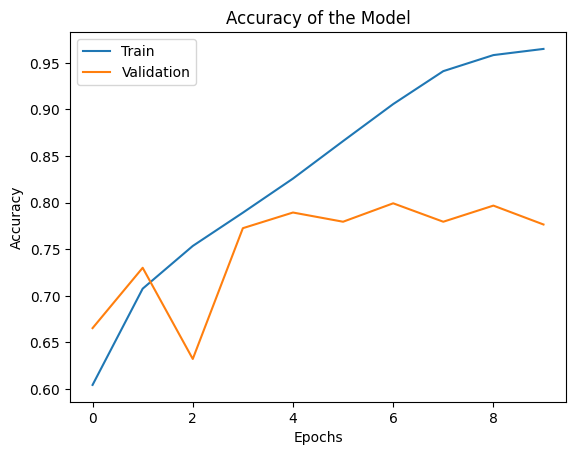

In [13]:
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title("Accuracy of the Model")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend(["Train", "Validation"])
plt.show()

*The graph above shows the training accuracy and validation accuracy of the CNN model over multiple epochs.*


1. The training accuracy steadily increases and reaches nearly 98%, indicating that the model is learning the patterns in the training dataset very well.

2. The validation accuracy improves initially and reaches around 80%, after which it becomes relatively stable.
